# Vehicle Make Model Recognition (VMMR) — EfficientNet-B4 (245 classes)

This notebook trains and evaluates a **Vehicle Make/Model Recognition (VMMR)** model using **PyTorch** and a pretrained **EfficientNet-B4** backbone.

## Dataset
- Zip: `dataset_245.zip`
- Extracted structure:
  - `dataset/train/<class_name>/*`
  - `dataset/test/<class_name>/*`

## Outputs
- Best checkpoint saved to Google Drive
- Final test metrics (Top-1/Top-5 + macro metrics + FPR)
- Metric heatmap, confusion-matrix chunks (50-class blocks), and 20 random test predictions with Top-5 probabilities


In [ ]:
# If you see a prompt about restarting the runtime after installs, do so once.

import os
import random
import math
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import transforms
from torchvision.datasets import ImageFolder

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

import matplotlib.pyplot as plt

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))


torch: 2.10.0+cu128
torchvision: 0.25.0+cu128
cuda available: True
gpu: Tesla T4


In [ ]:
# Mount Google Drive (Colab)
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Paths
# Update ZIP_PATH if your zip is in a different Drive folder.
ZIP_PATH = "/content/drive/MyDrive/dataset_245.zip"
EXTRACT_ROOT = "/content"  # extracts to /content/dataset/
DATASET_ROOT = os.path.join(EXTRACT_ROOT, "dataset")
TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
TEST_DIR = os.path.join(DATASET_ROOT, "test")

# Checkpoint (saved to Drive)
CKPT_DIR = "/content/drive/MyDrive/vmmr_checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)
BEST_CKPT_PATH = os.path.join(CKPT_DIR, "efficientnet_b4_best.pth")

print("ZIP_PATH:", ZIP_PATH)
print("DATASET_ROOT:", DATASET_ROOT)
print("BEST_CKPT_PATH:", BEST_CKPT_PATH)


ZIP_PATH: /content/drive/MyDrive/dataset_245.zip
DATASET_ROOT: /content/dataset
BEST_CKPT_PATH: /content/drive/MyDrive/vmmr_checkpoints/efficientnet_b4_best.pth


In [ ]:
# Extract dataset_245.zip (only if needed)
import subprocess
from pathlib import Path

def _looks_like_split_root(root: Path) -> bool:
    """Heuristic: root/train and root/test exist and train has class subfolders."""
    train_dir = root / "train"
    test_dir = root / "test"
    if not (train_dir.is_dir() and test_dir.is_dir()):
        return False

    # Require at least one class directory under train
    try:
        any_class_dir = any(p.is_dir() for p in train_dir.iterdir())
    except Exception:
        any_class_dir = False

    return any_class_dir


def _find_dataset_root(search_root: str) -> str | None:
    """Find a directory that contains train/ and test/ as direct children.

    Supports common layouts:
    - /content/dataset/train + /content/dataset/test
    - /content/<something>/dataset/train + /content/<something>/dataset/test
    - /content/<something>/train + /content/<something>/test
    """
    search_root_p = Path(search_root)

    # Fast common checks
    for candidate in [search_root_p / "dataset", search_root_p]:
        if _looks_like_split_root(candidate):
            return str(candidate)

    # Search for any sibling train/test directories anywhere under extract_root
    # (Some zips extract to dataset_245/train and dataset_245/test, etc.)
    train_hits = []
    for train_path in search_root_p.glob("**/train"):
        if not train_path.is_dir():
            continue
        root = train_path.parent
        if _looks_like_split_root(root):
            return str(root)
        train_hits.append(str(train_path))

    # Fallback: search for **/dataset/train specifically
    for train_path in search_root_p.glob("**/dataset/train"):
        root = train_path.parent
        if _looks_like_split_root(root):
            return str(root)

    print("Could not auto-locate dataset root.")
    if train_hits:
        print("Found train-like directories (first 10):")
        for p in train_hits[:10]:
            print("-", p)
    else:
        print("No 'train' directories found under:", search_root)

    # Show top-level of extract_root to help debugging
    try:
        top = [p.name for p in search_root_p.iterdir()][:50]
        print("Top-level entries under extract_root (first 50):", top)
    except Exception as e:
        print("Failed listing extract_root:", e)

    return None


def ensure_extracted(zip_path: str, extract_root: str, dataset_root_hint: str):
    """Extract zip into extract_root and resolve actual dataset root."""
    hint_root = Path(dataset_root_hint)
    if _looks_like_split_root(hint_root):
        print("Dataset already extracted:", str(hint_root))
        return str(hint_root)

    # Also: if something was previously extracted elsewhere under extract_root
    existing = _find_dataset_root(extract_root)
    if existing is not None:
        print("Dataset already present under extract_root:", existing)
        return existing

    if not os.path.isfile(zip_path):
        raise FileNotFoundError(
            f"Zip not found at {zip_path}. Please upload to Drive and set ZIP_PATH accordingly."
        )

    print("Extracting zip... this can take several minutes for ~6.4GB.")

    # Use system unzip (fast in Colab)
    cmd = ["unzip", "-q", "-o", zip_path, "-d", extract_root]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError("Unzip failed.")

    resolved = _find_dataset_root(extract_root)
    if resolved is None:
        raise RuntimeError(
            "Extraction completed but dataset root could not be located. "
            "Expected to find sibling train/ and test/ folders somewhere under extract_root."
        )

    print("Extraction complete. Resolved dataset root:", resolved)
    return resolved

# Resolve actual dataset root (supports extra top-level folder inside the zip)
DATASET_ROOT = ensure_extracted(ZIP_PATH, EXTRACT_ROOT, DATASET_ROOT)
TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
TEST_DIR = os.path.join(DATASET_ROOT, "test")

print("Train dir:", TRAIN_DIR)
print("Test dir:", TEST_DIR)
print("Train dir exists:", os.path.isdir(TRAIN_DIR))
print("Test dir exists:", os.path.isdir(TEST_DIR))


Could not auto-locate dataset root.
No 'train' directories found under: /content
Top-level entries under extract_root (first 50): ['.config', 'drive', 'sample_data']
Extracting zip... this can take several minutes for ~6.4GB.
Extraction complete. Resolved dataset root: /content/dataset_245
Train dir: /content/dataset_245/train
Test dir: /content/dataset_245/test
Train dir exists: True
Test dir exists: True


In [ ]:
# Automatically detect class names and number of classes
# (ImageFolder reads subfolder names as classes)

tmp_ds = ImageFolder(TRAIN_DIR)
class_names = tmp_ds.classes
num_classes = len(class_names)

print("Detected classes:", num_classes)
print("First 10 class names:", class_names[:10])
assert num_classes == 245, f"Expected 245 classes, found {num_classes}."


Detected classes: 245
First 10 class names: ['Audi_A4', 'Audi_A6', 'BYD_Atto 3', 'BYD_Shark 6', 'Bmw_3 Series', 'Bmw_series7_7 Series 2021 2025', 'Changan_Alsvin', 'Changan_karvaan', 'Changan_oshan_x7', 'Chery_Tiggo 4 Pro']


In [ ]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


In [ ]:
# Transforms
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


In [ ]:
# Datasets + train/val split (80/20) created from training set
# Also ignore corrupted/unreadable images (ImageFolder would crash otherwise).

from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

VERIFY_CORRUPT_IMAGES = True  # set False to skip scanning
MAX_CORRUPT_LOG = 20         # print details for first N corrupt files


class FilteredImageFolder(ImageFolder):
    """ImageFolder variant that can filter out invalid samples by index."""

    def __init__(self, root, transform=None, valid_indices=None):
        super().__init__(root, transform=transform)
        if valid_indices is not None:
            valid_set = set(valid_indices)
            # Keep ordering stable; just drop invalid entries.
            self.samples = [s for i, s in enumerate(self.samples) if i in valid_set]
            self.targets = [t for _, t in self.samples]


def get_valid_indices(imgfolder_ds: ImageFolder):
    valid = []
    corrupt = 0

    for i, (path, _) in enumerate(tqdm(imgfolder_ds.samples, desc="Scanning images", leave=False)):
        try:
            with Image.open(path) as img:
                img.verify()  # verify does a deep enough check to catch many corrupt files
            valid.append(i)
        except Exception as e:
            corrupt += 1
            if corrupt <= MAX_CORRUPT_LOG:
                print(f"Skipping corrupted image: {path}\n  Reason: {type(e).__name__}: {e}")

    print(f"Invalid/corrupted images skipped: {corrupt}")
    return valid


# Base datasets (no transforms) used only for scanning + consistent sample ordering.
train_base_nofmt = ImageFolder(TRAIN_DIR)
valid_train_indices = list(range(len(train_base_nofmt.samples)))

test_base_nofmt = ImageFolder(TEST_DIR)
valid_test_indices = list(range(len(test_base_nofmt.samples)))

if VERIFY_CORRUPT_IMAGES:
    valid_train_indices = get_valid_indices(train_base_nofmt)
    valid_test_indices = get_valid_indices(test_base_nofmt)

if len(valid_train_indices) == 0:
    raise RuntimeError("No valid training images left after filtering."
                       " Check dataset integrity/corruption.")

if len(valid_test_indices) == 0:
    raise RuntimeError("No valid test images left after filtering."
                       " Check dataset integrity/corruption.")

# Create filtered datasets with transforms
full_train_ds_for_split = FilteredImageFolder(
    TRAIN_DIR, transform=None, valid_indices=valid_train_indices
)

n_total = len(full_train_ds_for_split)
n_train = int(0.8 * n_total)
n_val = n_total - n_train

perm = torch.randperm(
    n_total, generator=torch.Generator().manual_seed(SEED)
).tolist()
train_indices = perm[:n_train]
val_indices = perm[n_train:]

train_filtered_ds = FilteredImageFolder(TRAIN_DIR, transform=train_tfms, valid_indices=valid_train_indices)
val_filtered_ds = FilteredImageFolder(TRAIN_DIR, transform=eval_tfms, valid_indices=valid_train_indices)

test_ds = FilteredImageFolder(TEST_DIR, transform=eval_tfms, valid_indices=valid_test_indices)

train_ds = Subset(train_filtered_ds, train_indices)
val_ds = Subset(val_filtered_ds, val_indices)

# Ensure class mapping matches across datasets
base_train = train_ds.dataset
base_val = val_ds.dataset
assert base_train.class_to_idx == base_val.class_to_idx == test_ds.class_to_idx

print("Images:")
print("- train:", len(train_ds))
print("- val:", len(val_ds))
print("- test:", len(test_ds))
print("Classes:", len(test_ds.classes))


Scanning images:   0%|          | 0/39882 [00:00<?, ?it/s]

Skipping corrupted image: /content/dataset_245/train/Kia_Sorento/kia-sorento-2-4-awd-2022-138637966.webp
  Reason: UnidentifiedImageError: cannot identify image file '/content/dataset_245/train/Kia_Sorento/kia-sorento-2-4-awd-2022-138637966.webp'
Invalid/corrupted images skipped: 1


Scanning images:   0%|          | 0/17254 [00:00<?, ?it/s]

Invalid/corrupted images skipped: 0
Images:
- train: 31904
- val: 7977
- test: 17254
Classes: 245


In [ ]:
# DataLoaders (auto batch size by GPU memory)

def pick_batch_size():
    if not torch.cuda.is_available():
        return 16
    mem_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    return 32 if mem_gb >= 12 else 16

batch_size = pick_batch_size()
num_workers = 2
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
    drop_last=False,
)
val_loader = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    drop_last=False,
)
test_loader = DataLoader(
    test_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
    drop_last=False,
)

print("batch_size:", batch_size)
print("num_workers:", num_workers)
print("pin_memory:", pin_memory)


batch_size: 32
num_workers: 2
pin_memory: True


In [ ]:
# Model: pretrained EfficientNet-B4 with replaced classifier
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights

weights = EfficientNet_B4_Weights.IMAGENET1K_V1
model = efficientnet_b4(weights=weights)

# Replace classifier
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

model = model.to(device)

# Optional: enable cuDNN autotune
torch.backends.cudnn.benchmark = True

print(model.__class__.__name__)
print("Classifier out:", model.classifier[1].out_features)


Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 134MB/s]


EfficientNet
Classifier out: 245


In [ ]:
# Loss, optimizer, scheduler, early stopping, checkpoint utilities

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=1e-4)

# Some Colab/PyTorch builds don't support ReduceLROnPlateau(verbose=...)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)


def save_checkpoint(path, model, optimizer, scheduler, epoch, best_val_loss, class_names, history):
    ckpt = {
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,
        "epoch": epoch,
        "best_val_loss": best_val_loss,
        "class_names": class_names,
        "history": history,
    }
    torch.save(ckpt, path)


def load_checkpoint(path, model, optimizer=None, scheduler=None, map_location="cpu"):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and "optimizer_state" in ckpt and ckpt["optimizer_state"] is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None and "scheduler_state" in ckpt and ckpt["scheduler_state"] is not None:
        scheduler.load_state_dict(ckpt["scheduler_state"])
    return ckpt


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = None
        self.bad_epochs = 0

    def step(self, value):
        if self.best is None or value < (self.best - self.min_delta):
            self.best = value
            self.bad_epochs = 0
            return False  # do not stop
        self.bad_epochs += 1
        return self.bad_epochs >= self.patience


In [ ]:
# Modular training/eval functions

@torch.no_grad()
def _accuracy_from_logits(logits: torch.Tensor, targets: torch.Tensor) -> float:
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_acc = 0.0
    n_batches = 0

    pbar = tqdm(loader, desc="Train", leave=False)
    for images, targets in pbar:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        bs = images.size(0)
        running_loss += loss.item() * bs
        running_acc += _accuracy_from_logits(logits.detach(), targets) * bs
        n_batches += bs

        pbar.set_postfix({"loss": loss.item()})

    epoch_loss = running_loss / max(n_batches, 1)
    epoch_acc = running_acc / max(n_batches, 1)
    return epoch_loss, epoch_acc


@torch.no_grad()
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_acc = 0.0
    n_samples = 0

    pbar = tqdm(loader, desc="Val", leave=False)
    for images, targets in pbar:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, targets)

        bs = images.size(0)
        running_loss += loss.item() * bs
        running_acc += _accuracy_from_logits(logits, targets) * bs
        n_samples += bs

        pbar.set_postfix({"loss": loss.item()})

    val_loss = running_loss / max(n_samples, 1)
    val_acc = running_acc / max(n_samples, 1)
    return val_loss, val_acc


@torch.no_grad()
def test(model, loader, device, num_classes: int):
    model.eval()

    all_targets = []
    all_preds = []
    all_top5 = []

    for images, targets in tqdm(loader, desc="Test", leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(images)
        probs = torch.softmax(logits, dim=1)

        top1 = probs.argmax(dim=1)
        top5 = torch.topk(probs, k=min(5, num_classes), dim=1).indices

        all_targets.append(targets.detach().cpu().numpy())
        all_preds.append(top1.detach().cpu().numpy())
        all_top5.append(top5.detach().cpu().numpy())

    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_preds)
    y_top5 = np.concatenate(all_top5)

    top1_acc = (y_true == y_pred).mean().item()
    top5_acc = np.mean([y_true[i] in y_top5[i] for i in range(len(y_true))]).item()

    # Macro precision/recall/f1
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))

    # Macro FPR from confusion matrix (one-vs-all per class)
    # For class k: FP = sum column k excluding diagonal, TN = total - (TP + FP + FN)
    total = cm.sum()
    fprs = []
    for k in range(num_classes):
        tp = cm[k, k]
        fp = cm[:, k].sum() - tp
        fn = cm[k, :].sum() - tp
        tn = total - (tp + fp + fn)
        denom = (fp + tn)
        fpr_k = (fp / denom) if denom > 0 else 0.0
        fprs.append(fpr_k)
    fpr_macro = float(np.mean(fprs))

    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
        "fpr_macro": float(fpr_macro),
        "top1_acc": float(top1_acc),
        "top5_acc": float(top5_acc),
    }

    return metrics, cm, y_true, y_pred


In [ ]:
# Training loop (single phase) with early stopping + best-checkpoint only + resume support

EPOCHS = 50
PATIENCE = 5
RESUME = True  # set False to always start fresh

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "lr": [],
}

start_epoch = 0
best_val_loss = float("inf")

if RESUME and os.path.isfile(BEST_CKPT_PATH):
    ckpt = load_checkpoint(BEST_CKPT_PATH, model, optimizer, scheduler, map_location=device)
    start_epoch = int(ckpt.get("epoch", -1)) + 1
    best_val_loss = float(ckpt.get("best_val_loss", best_val_loss))
    history = ckpt.get("history", history)
    ckpt_classes = ckpt.get("class_names", None)
    if ckpt_classes is not None and ckpt_classes != class_names:
        print("Warning: class names in checkpoint differ from current dataset.")
    print(f"Resumed from checkpoint at epoch {start_epoch} (best_val_loss={best_val_loss:.4f})")
else:
    print("Starting training from scratch.")

early_stopper = EarlyStopping(patience=PATIENCE)

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    lr_before = optimizer.param_groups[0]["lr"]
    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]
    lr_note = "" if current_lr == lr_before else f" (lr reduced {lr_before:.2e} → {current_lr:.2e})"

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        save_checkpoint(
            BEST_CKPT_PATH,
            model,
            optimizer,
            scheduler,
            epoch=epoch,
            best_val_loss=best_val_loss,
            class_names=class_names,
            history=history,
        )

    should_stop = early_stopper.step(val_loss)

    dt = time.time() - t0
    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
        f"train_acc={train_acc:.4f} val_acc={val_acc:.4f} | "
        f"lr={current_lr:.2e}{lr_note} | "
        f"best_val_loss={best_val_loss:.4f} | "
        f"saved={'yes' if improved else 'no'} | "
        f"time={dt:.1f}s"
    )

    if should_stop:
        print(f"Early stopping triggered (patience={PATIENCE}).")
        break

print("Training complete. Best checkpoint:", BEST_CKPT_PATH)


Resumed from checkpoint at epoch 32 (best_val_loss=1.1059)


Train:   0%|          | 0/997 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Val:   0%|          | 0/250 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Train:   0%|          | 0/997 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Val:   0%|          | 0/250 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 50/50 | train_loss=1.1340 val_loss=1.0738 | train_acc=0.9583 val_acc=0.9641 | lr=5.00e-05 | best_val_loss=1.0738 | saved=yes | time=611.0s
Training complete. Best checkpoint: /content/drive/MyDrive/vmmr_checkpoints/efficientnet_b4_best.pth


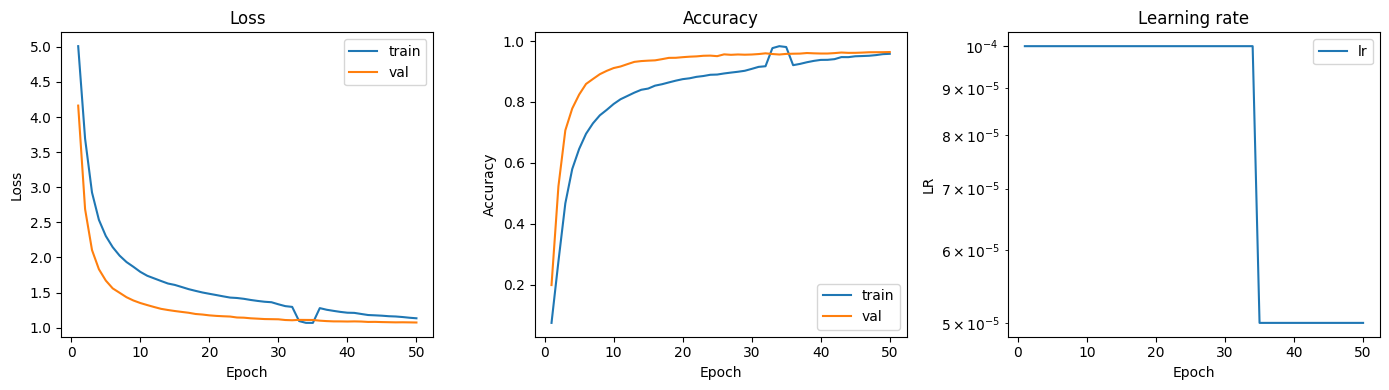

In [ ]:
# Plot training logs

def plot_history(history):
    epochs = np.arange(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(14, 4))

    plt.subplot(1, 3, 1)
    plt.plot(epochs, history["train_loss"], label="train")
    plt.plot(epochs, history["val_loss"], label="val")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 3, 2)
    plt.plot(epochs, history["train_acc"], label="train")
    plt.plot(epochs, history["val_acc"], label="val")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 3, 3)
    plt.plot(epochs, history["lr"], label="lr")
    plt.title("Learning rate")
    plt.xlabel("Epoch")
    plt.ylabel("LR")
    plt.yscale("log")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)


In [ ]:
# Load best model for testing
assert os.path.isfile(BEST_CKPT_PATH), "Best checkpoint not found."
ckpt = load_checkpoint(BEST_CKPT_PATH, model, optimizer=None, scheduler=None, map_location=device)
model = model.to(device)
model.eval()
print("Loaded best checkpoint with best_val_loss:", ckpt.get("best_val_loss"))


Loaded best checkpoint with best_val_loss: 1.073816375892623


In [ ]:
# Final evaluation on test set

test_metrics, cm, y_true, y_pred = test(model, test_loader, device, num_classes=num_classes)

print("\nFinal Test Metrics")
for k, v in test_metrics.items():
    print(f"- {k}: {v:.4f}")


Test:   0%|          | 0/540 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Final Test Metrics
- accuracy: 0.9624
- precision_macro: 0.9634
- recall_macro: 0.9612
- f1_macro: 0.9618
- fpr_macro: 0.0002
- top1_acc: 0.9624
- top5_acc: 0.9939


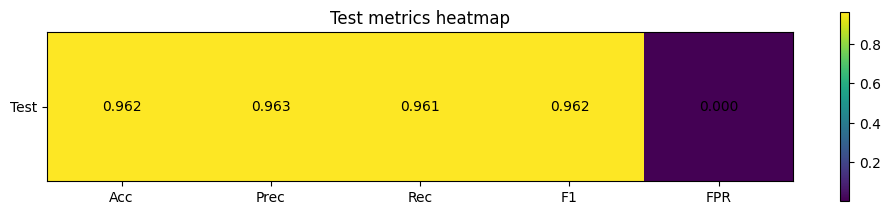

In [ ]:
# Performance heatmap (accuracy, precision, recall, F1, FPR)

keys = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "fpr_macro"]
vals = [test_metrics[k] for k in keys]

data = np.array(vals, dtype=np.float32).reshape(1, -1)

plt.figure(figsize=(10, 2.2))
plt.imshow(data)  # default colormap (no manual colors)
plt.yticks([0], ["Test"])
plt.xticks(np.arange(len(keys)), ["Acc", "Prec", "Rec", "F1", "FPR"], rotation=0)

for j, v in enumerate(vals):
    plt.text(j, 0, f"{v:.3f}", ha="center", va="center")

plt.colorbar()
plt.title("Test metrics heatmap")
plt.tight_layout()
plt.show()


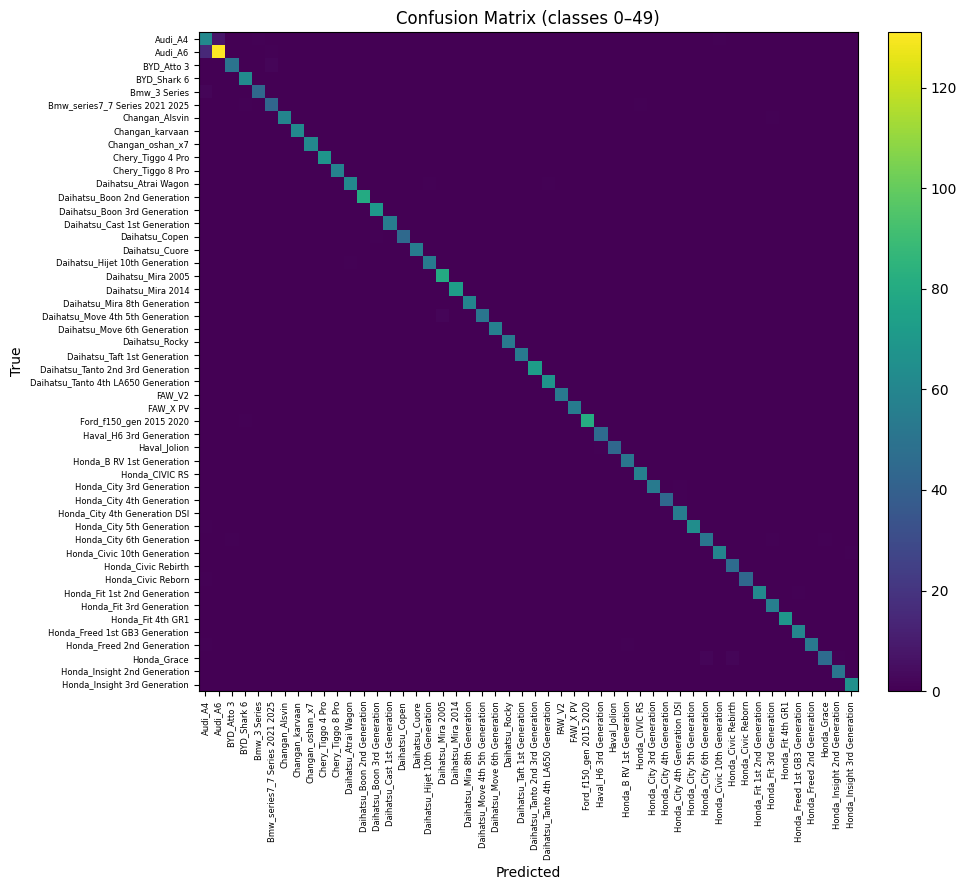

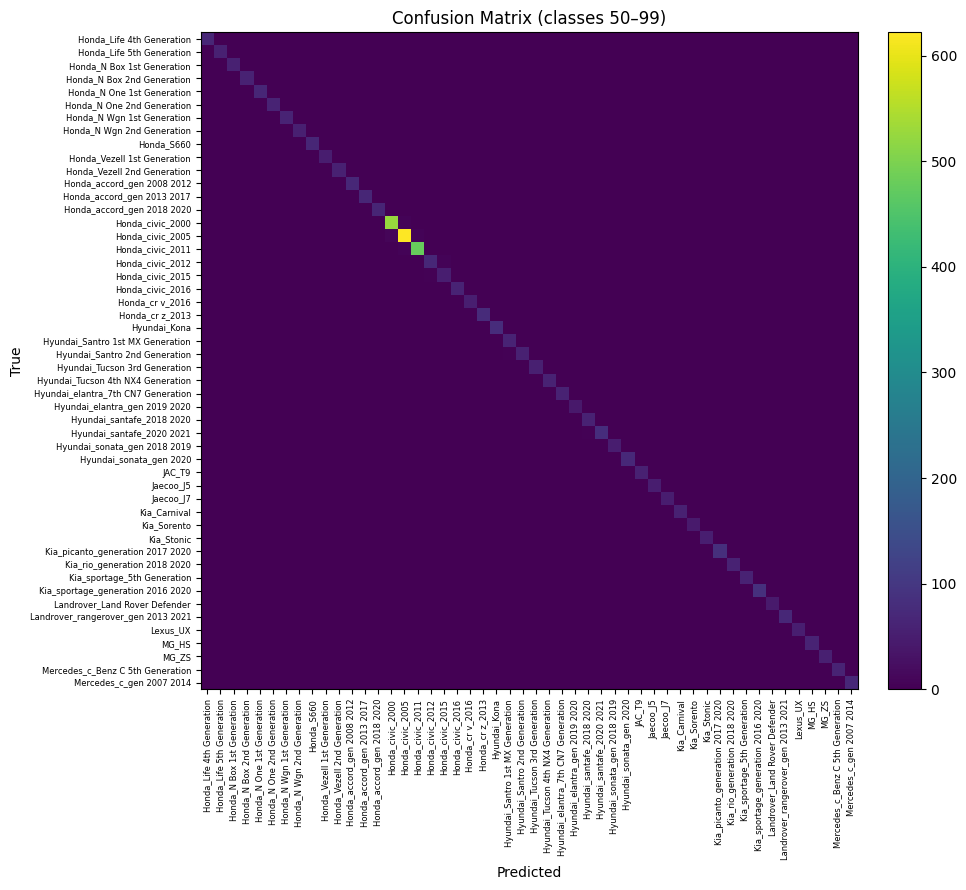

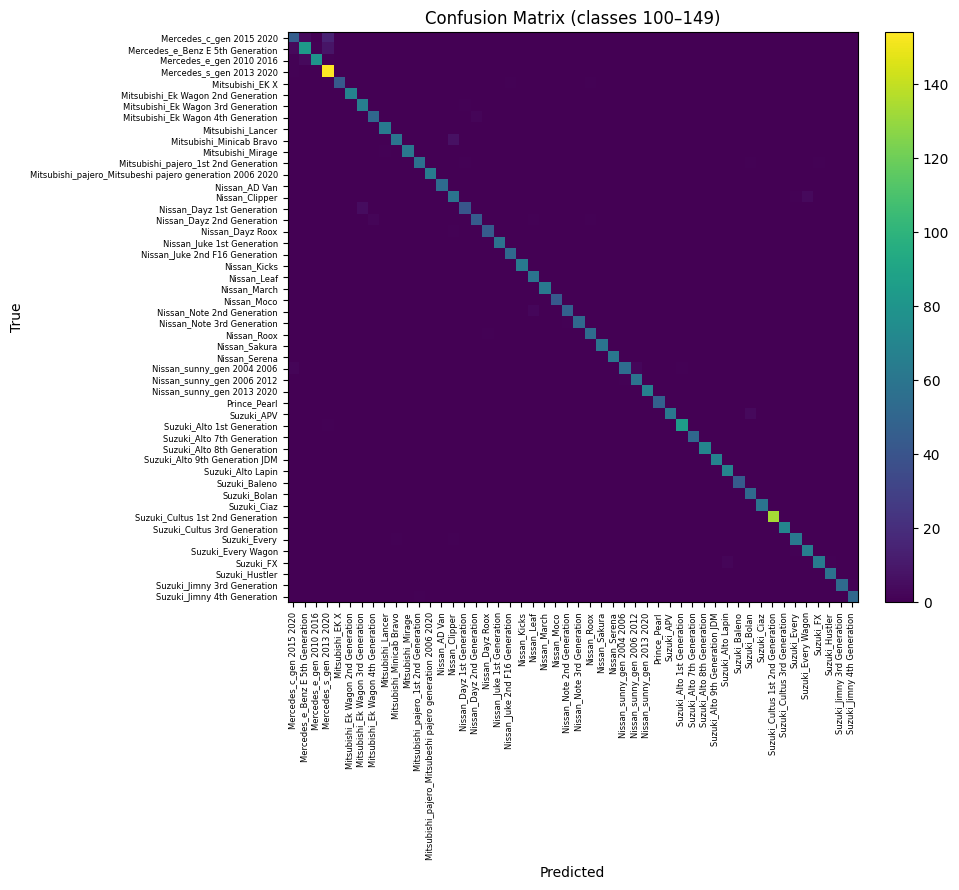

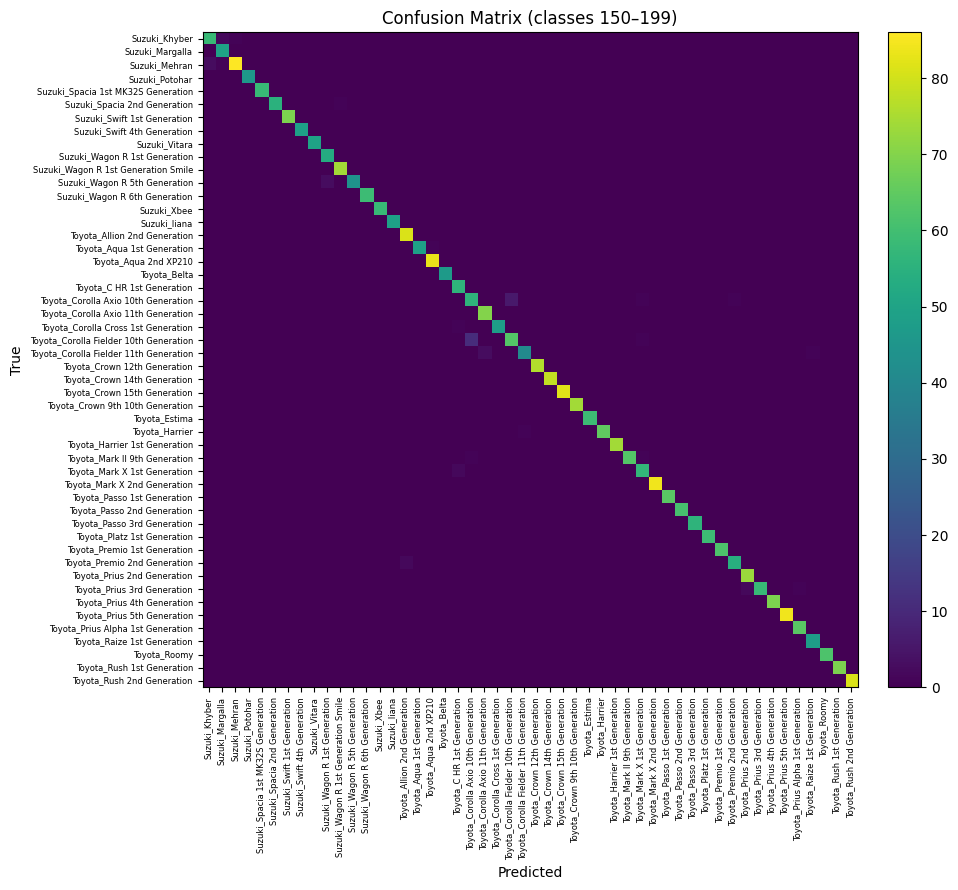

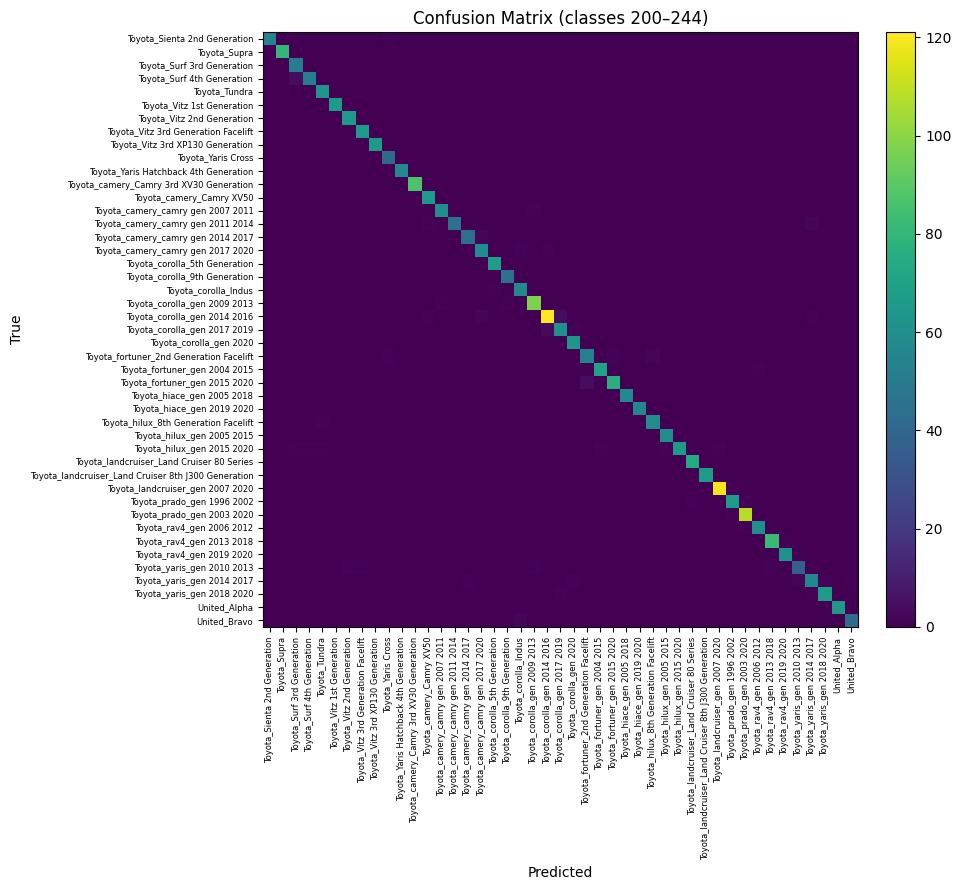

In [ ]:
# Confusion matrix plots in chunks of 50 classes

idx_to_class = {v: k for k, v in test_ds.class_to_idx.items()}


def plot_confusion_matrix_chunk(cm, class_names_ordered, start, end):
    sub = cm[start:end, start:end]
    labels = class_names_ordered[start:end]

    plt.figure(figsize=(10, 9))
    plt.imshow(sub)  # default colormap
    plt.colorbar(fraction=0.046, pad=0.04)

    plt.title(f"Confusion Matrix (classes {start}–{end-1})")
    plt.xlabel("Predicted")
    plt.ylabel("True")

    ticks = np.arange(len(labels))
    plt.xticks(ticks, labels, rotation=90, fontsize=6)
    plt.yticks(ticks, labels, fontsize=6)

    plt.tight_layout()
    plt.show()


ordered_class_names = [idx_to_class[i] for i in range(num_classes)]
chunk_size = 50

for start in range(0, num_classes, chunk_size):
    end = min(start + chunk_size, num_classes)
    plot_confusion_matrix_chunk(cm, ordered_class_names, start, end)


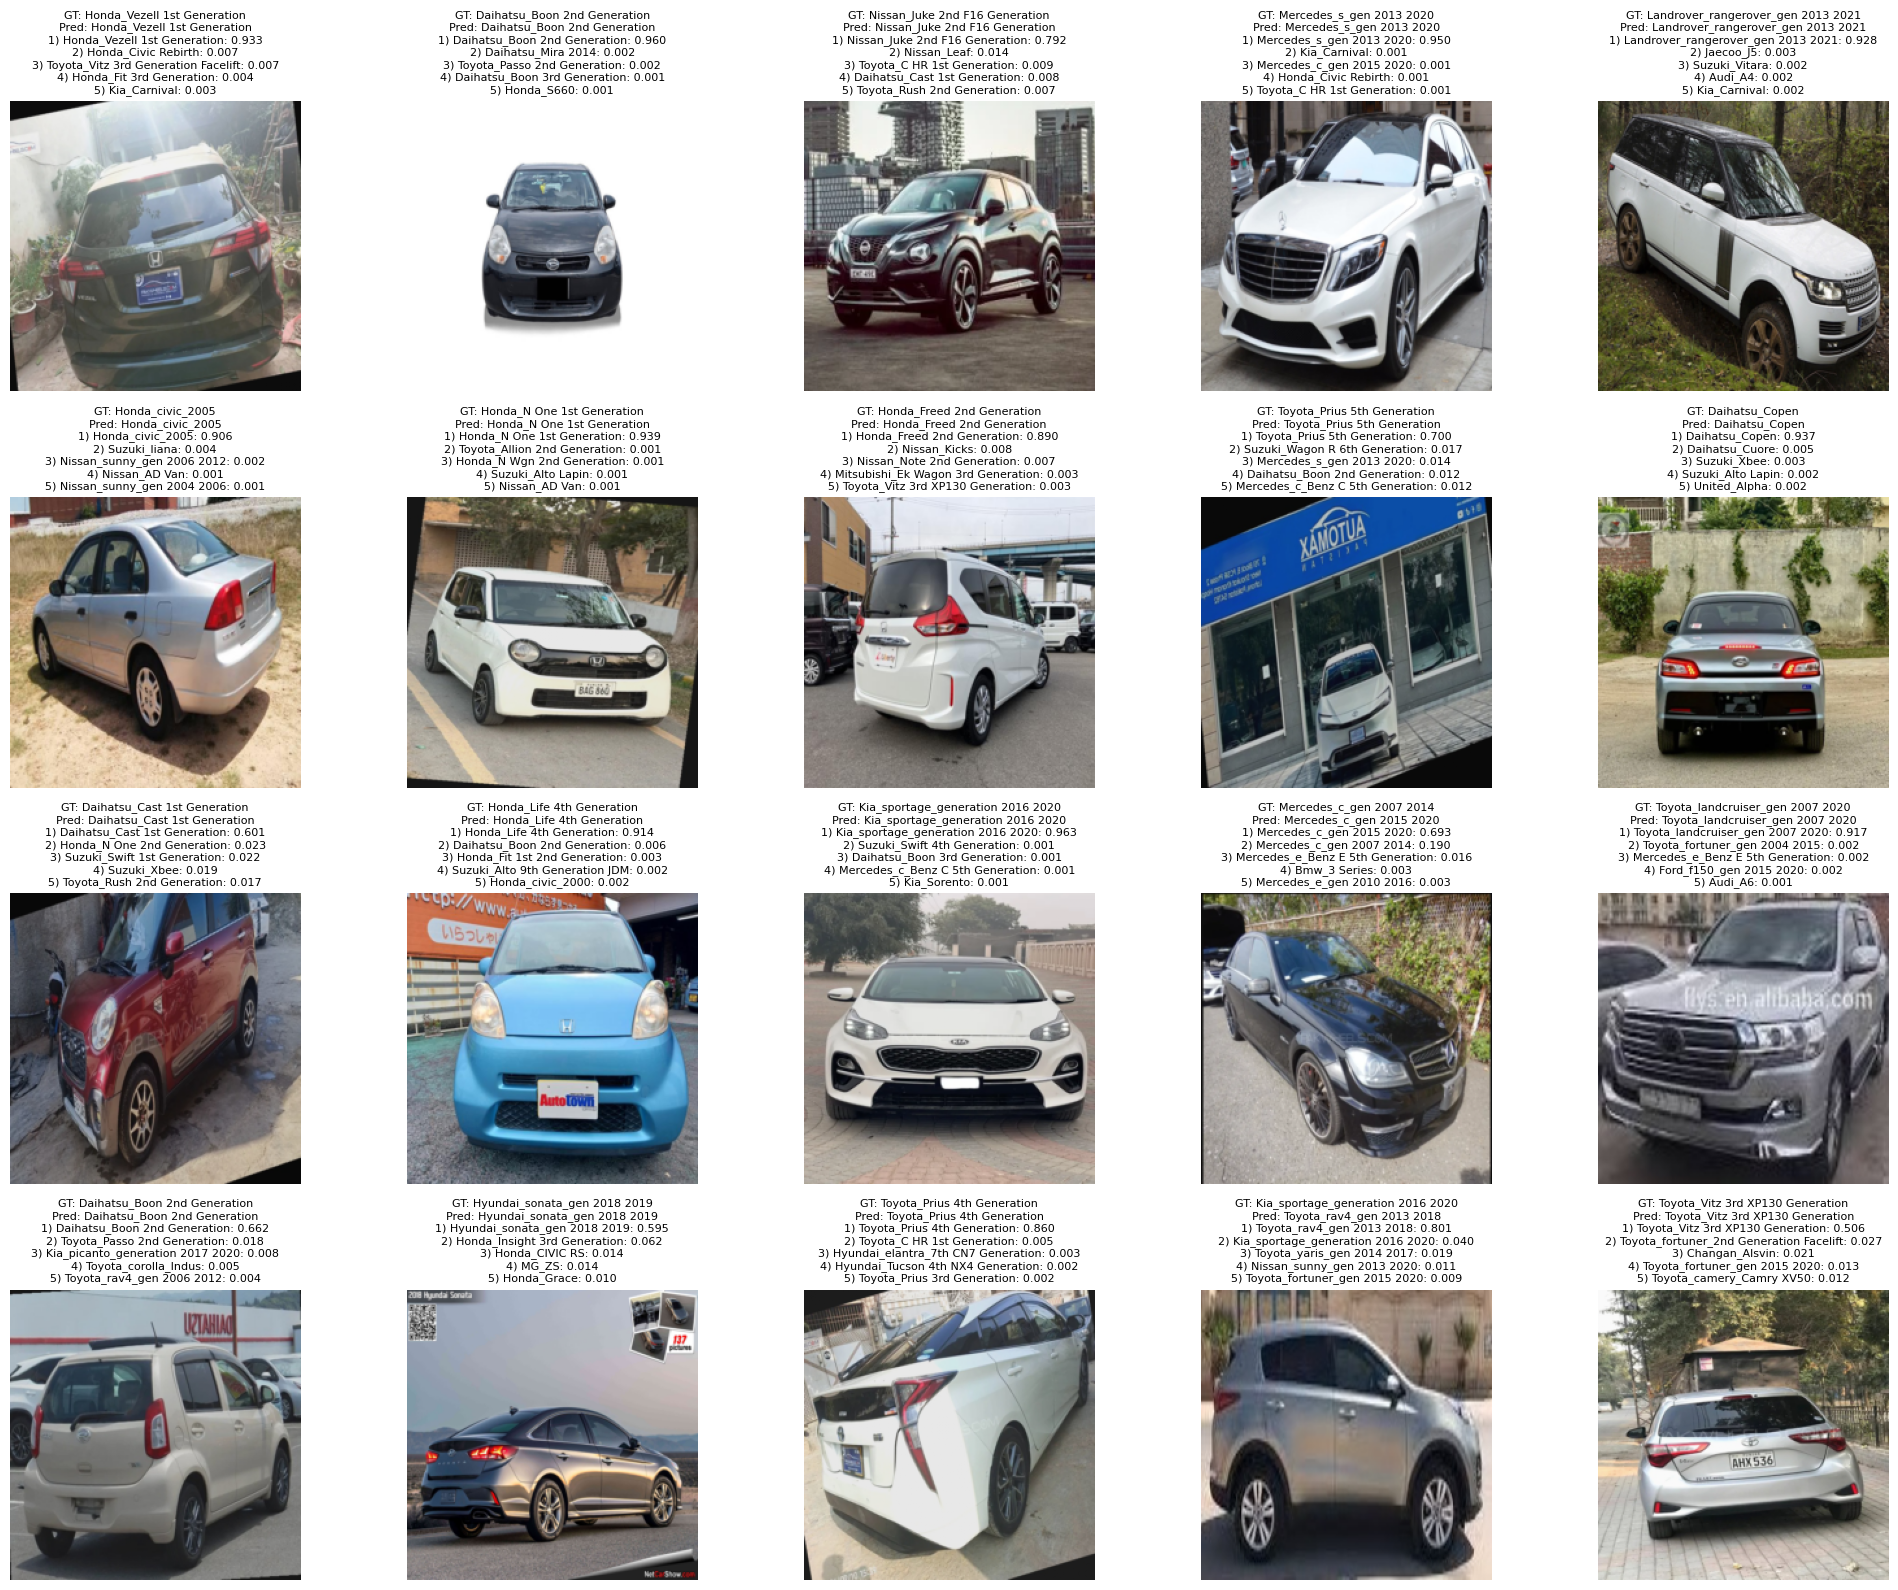

In [ ]:
# Visualize 20 random test predictions with Top-5 probabilities

# For visualization, we need unnormalized images
viz_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Use the same "ignore corrupted" filter as the test dataset
raw_test_ds = FilteredImageFolder(TEST_DIR, transform=viz_tfms, valid_indices=valid_test_indices)
assert raw_test_ds.class_to_idx == test_ds.class_to_idx


@torch.no_grad()
def predict_topk(model, image_tensor, k=5):
    """image_tensor is unnormalized (ToTensor only)."""
    model.eval()
    x = image_tensor.unsqueeze(0).to(device)

    # Apply eval normalization
    x_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)(x.squeeze(0)).unsqueeze(0)

    logits = model(x_norm)
    probs = torch.softmax(logits, dim=1).squeeze(0)
    topk = torch.topk(probs, k=min(k, probs.numel()))

    return topk.indices.detach().cpu().numpy(), topk.values.detach().cpu().numpy()


n_show = 20
indices = random.sample(range(len(raw_test_ds)), k=min(n_show, len(raw_test_ds)))

cols = 5
rows = math.ceil(len(indices) / cols)
plt.figure(figsize=(4 * cols, 4 * rows))

for i, idx in enumerate(indices):
    img_tensor, y = raw_test_ds[idx]

    top_idx, top_prob = predict_topk(model, img_tensor, k=5)
    pred = int(top_idx[0])

    # Convert to displayable image
    disp = img_tensor.permute(1, 2, 0).numpy()
    disp = np.clip(disp, 0, 1)

    gt_name = ordered_class_names[y]
    pred_name = ordered_class_names[pred]

    top5_lines = []
    for j in range(len(top_idx)):
        top5_lines.append(f"{j+1}) {ordered_class_names[int(top_idx[j])]}: {float(top_prob[j]):.3f}")

    title = f"GT: {gt_name}\nPred: {pred_name}\n" + "\n".join(top5_lines)

    ax = plt.subplot(rows, cols, i + 1)
    ax.imshow(disp)
    ax.set_title(title, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Predict top-5 classes for uploaded image
# Also downloads the best .pth checkpoint in Colab.

idx_to_name = ordered_class_names if "ordered_class_names" in globals() else class_names

top_idx, top_prob = predict_topk(model, uploaded_tensor, k=5)

print("Top-5 predictions:")
for rank, (cls_idx, prob) in enumerate(zip(top_idx, top_prob), start=1):
    print(f"{rank}. {idx_to_name[int(cls_idx)]} ({float(prob)*100:.2f}%)")

# Download checkpoint (.pth) in Colab
try:
    from google.colab import files
    if os.path.exists(BEST_CKPT_PATH):
        files.download(BEST_CKPT_PATH)
        print(f"Downloading: {BEST_CKPT_PATH}")
    else:
        print(f"Checkpoint not found at: {BEST_CKPT_PATH}")
except Exception as e:
    print("Auto-download is available in Colab only.")
    print("If needed, manually copy this file:", BEST_CKPT_PATH)
    print("Detail:", e)

NameError: name 'uploaded_tensor' is not defined

In [ ]:
# Save detected class names to classes.txt
# One class name per line, in the same order as ImageFolder.

classes_txt_path = os.path.join(DATASET_ROOT, "classes.txt")

with open(classes_txt_path, "w", encoding="utf-8") as f:
    for name in class_names:
        f.write(f"{name}\n")

print(f"Saved classes.txt to: {classes_txt_path}")
print(f"Total classes written: {len(class_names)}")


Saved classes.txt to: /content/dataset_245/classes.txt
Total classes written: 245


## Notes

- If extraction is slow, keep the tab open; `unzip` on ~6.4GB can take a while.
- If you hit GPU OOM, lower `batch_size` manually.
- The checkpoint saved in Drive (`efficientnet_b4_best.pth`) can be reused across sessions.
